# 19 真实工业钢材缺陷：从像素到类别和ROI框

本课面对热轧钢带表面质量检查，使用东北大学 NEU-DET 的1800张真实200×200灰度图：
龟裂、夹杂、斑块、麻点、氧化铁皮压入、划痕，按文件名主类别每类300张。
原作者提供图像与人工缺陷框；本课不把随机形状图当成工业数据。

学习路线：下载与核查 → VOC标注转JSON/CSV → 训练/验证/测试 →
原图与ROI → 卷积乘加 → 激活 → 池化 → 多通道卷积 →
特征向量 → 类别与框两个输出 → 各自的损失 → 反向传播 → 独立测试。

分类头回答“是什么”，定位头回答“在哪里”。本课显式增加一个框回归头；
它预测同类缺陷的联合包围框，不是多目标检测器。
特征图不是一张逐渐模糊的照片：空间分辨率会下降，通道学到的表示会改变。

首次执行要下载固定版本数据镜像，数据保存在data目录；以后可离线复用。
需要先学习06分类和07检测。默认CPU，PyTorch自动选择可用设备。

In [1]:
from pathlib import Path
import sys, copy, json, csv
sys.path.insert(0, str(Path.cwd().parent))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from course_utils import setup, device, save_figure
from industrial_data import prepare_neu, CLASSES, CHINESE
ROOT = setup(42)
DEV = device()
DATA, manifest = prepare_neu()
rows = manifest['samples']
print('设备:', DEV, '图像数:', len(rows))
print('固定镜像commit:', manifest['mirror_commit'])
print('压缩包SHA256:', manifest['archive_sha256'])

设备: cpu 图像数: 1800
固定镜像commit: 351bee21b56bbf97a1e1d18262bceb202eb7ef41
压缩包SHA256: e0f360b032342399d18ca14328e9eff905e7ac18cb5b1bc91f1fd20512e267d6


## 1 标注怎样保存：类别、多个框、图像尺寸

VOC XML每个object包含name和bndbox。原图坐标原点在左上，x向右，y向下；
本课将常见VOC的1-based闭区间转为0-based半开区间[x0,y0,x1,y1)，
裁剪直接使用image[y0:y1, x0:x1]。绘图与损失都沿用同一约定。
XML本身未声明坐标原点；这里记录所采用的转换，便于替换数据时复查。

一张图可能有多个同类框，也可能附带其他类别。本课保留全部原始标注，
以文件名主类别做6选1分类；这只是数据的单标签教学视角，不声称图片只有一种缺陷。
框回归目标是主类别所有框的联合外接矩形，其他类别框不混入该目标。
保留每个原框，避免把“联合框”说成原始标注。实际多类共现任务应使用多标签分类或完整多目标检测。

<annotation>
	<folder>sc</folder>
	<filename>scratches_1.jpg</filename>
	<source>
  		 <database>NEU-DET</database>
	</source>
	<size>
		<width>200</width>
		<height>200</height>
		<depth>1</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>scratches</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>26</xmin>
			<ymin>12</ymin>
			<xmax>43</xmax>
			<ymax>171</ymax>
		</bndbox>
	</object>
	<object>
		<name>scratches</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>1</difficult>
		<bndbox>
			<xmin>8</xmin>
			<ymin>184</ymin>
			<xmax>17</xmax>
			<ymax>196</ymax>
		</bndbox>
	</object>
</annotation>

解析后的JSON:
{
  "id": "scratches_1",
  "image": "images/scratches_1.jpg",
  "annotation": "annotations/scratches_1.xml",
  "label": "scratches",
  "label_id": 5,
  "width": 200,
  "height": 200,
  "objects": [
    {
      "label": "scratches",
      "xyxy": [
        25,
        11,
        43,
    

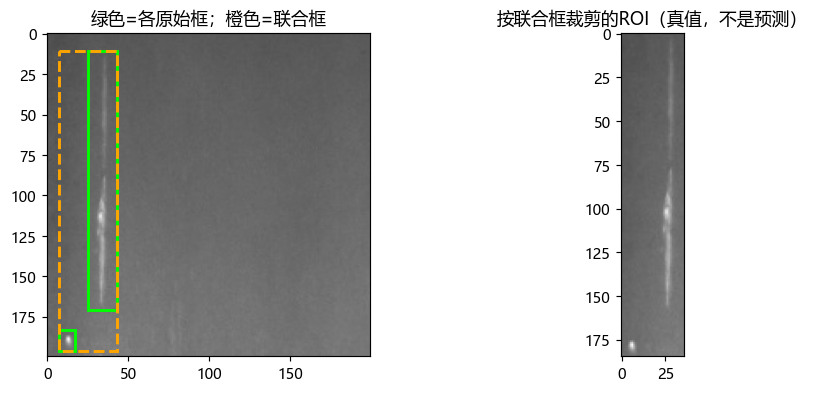

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/19_neu_annotation_roi.png')

In [2]:
sample = next(r for r in rows if r['label']=='scratches' and r['split']=='train')
raw = cv2.imread(str(DATA/sample['image']), cv2.IMREAD_GRAYSCALE)
print((DATA/sample['annotation']).read_text(encoding='utf-8')[:1800])
print('解析后的JSON:')
print(json.dumps(sample, ensure_ascii=False, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].imshow(raw,cmap='gray',vmin=0,vmax=255)
for obj in sample['objects']:
    x0,y0,x1,y1 = obj['xyxy']
    axes[0].add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color='lime',lw=2))
x0,y0,x1,y1=sample['union_xyxy']
axes[0].add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color='orange',lw=2,linestyle='--'))
axes[0].set_title('绿色=各原始框；橙色=联合框')
axes[1].imshow(raw[y0:y1,x0:x1],cmap='gray',vmin=0,vmax=255)
axes[1].set_title('按联合框裁剪的ROI（真值，不是预测）')
save_figure('19_neu_annotation_roi')

## 2 划分数据：先分原图，再做缩放或增强

采用固定种子42、按类别分层的70%训练/15%验证/15%测试教学划分。
相同解码像素的图片按SHA256分在同一组，禁止同图跨集合。
训练集拟合权重和归一化参数；验证集选检查点；测试集只在定型后评价一次。
这不是镜像作者给出的Validation目录划分，也不冒充原论文基准结果。
近重复图和同一产线批次仍可能相关；数据没有可靠批次ID，不能宣称已消除所有域泄漏。

集合总数: {'train': 1259, 'val': 270, 'test': 271}
每行train/val/test，每列六个类别:
[[210 210 209 210 210 210]
 [ 45  45  45  45  45  45]
 [ 45  45  46  45  45  45]]
已生成: D:\workspace\cv\cv-beginner-course\data\neu_det\train.csv D:\workspace\cv\cv-beginner-course\data\neu_det\val.csv D:\workspace\cv\cv-beginner-course\data\neu_det\test.csv


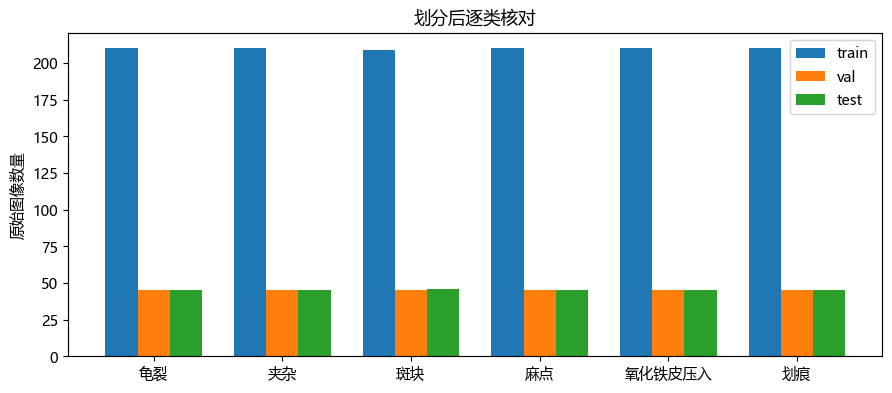

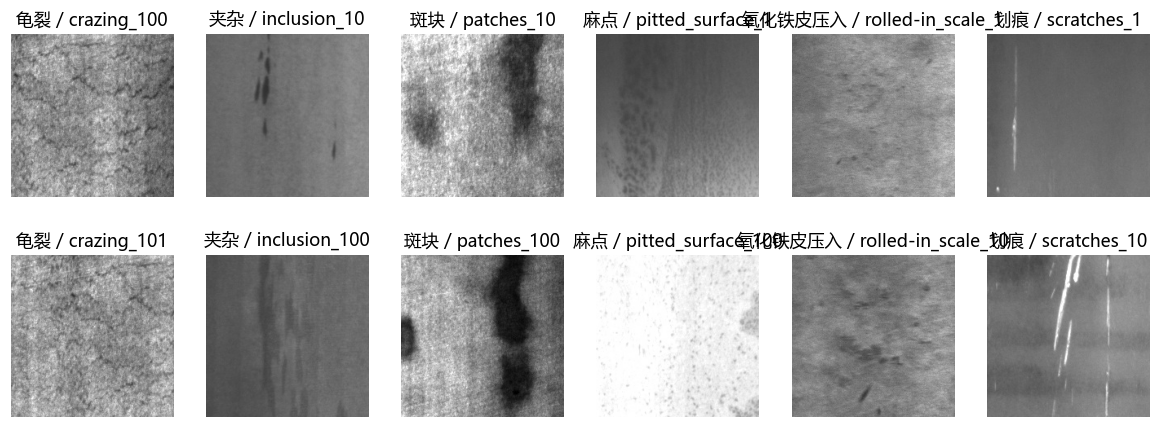

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/19_neu_real_inputs.png')

In [3]:
splits={s:[r for r in rows if r['split']==s] for s in ['train','val','test']}
hashes={s:{r['pixel_sha256'] for r in rs} for s,rs in splits.items()}
assert not (hashes['train'] & hashes['val'] or hashes['train'] & hashes['test'] or hashes['val'] & hashes['test'])
counts=np.array([[sum(r['label']==c for r in splits[s]) for c in CLASSES] for s in splits])
print('集合总数:',{s:len(v) for s,v in splits.items()})
print('每行train/val/test，每列六个类别:', counts, sep='\n')
print('已生成:',*[str(DATA/(s+'.csv')) for s in splits])
fig,ax=plt.subplots(figsize=(10,4)); x=np.arange(6)
for i,(s,row) in enumerate(zip(splits,counts)): ax.bar(x+(i-1)*.25,row,width=.25,label=s)
ax.set_xticks(x,CHINESE);ax.set_ylabel('原始图像数量');ax.legend();ax.set_title('划分后逐类核对')
save_figure('19_neu_splits')
fig,axs=plt.subplots(2,6,figsize=(14,5))
for c in range(6):
    examples=[r for r in splits['train'] if r['label_id']==c][:2]
    for j,r in enumerate(examples):
        axs[j,c].imshow(cv2.imread(str(DATA/r['image']),0),cmap='gray',vmin=0,vmax=255)
        axs[j,c].set_title(CHINESE[c]+' / '+r['id']);axs[j,c].axis('off')
save_figure('19_neu_real_inputs')

## 3 从200×200原图变成N×1×64×64张量

灰度图只有1个输入通道。RGB才是3个通道，不应为凑数把灰度强行解释成三种颜色。
64×64是本课堂的CPU折中；缩小会丢失细微缺陷，不能假设部署时同样合适。
框的四个坐标除以原始宽/高变为[0,1]；缩放到任意输入尺寸后，归一化框保持一致。
仅使用训练集计算均值和标准差。

训练集均值/标准差: 0.5044153332710266 0.20987090468406677
图像、类别、框: (1259, 1, 64, 64) (1259,) (1259, 4)
一个4×4像素块:
[[0.44705883 0.40784314 0.3764706  0.41568628]
 [0.47843137 0.43529412 0.3647059  0.45490196]
 [0.45490196 0.4862745  0.43529412 0.43137255]
 [0.5372549  0.5058824  0.4745098  0.45882353]]
对应标准化张量:
[[-0.27329424 -0.46015045 -0.6096354  -0.4227792 ]
 [-0.12380925 -0.3293511  -0.66569227 -0.23592298]
 [-0.23592298 -0.08643801 -0.3293511  -0.3480367 ]
 [ 0.15647522  0.00699025 -0.14249487 -0.21723735]]


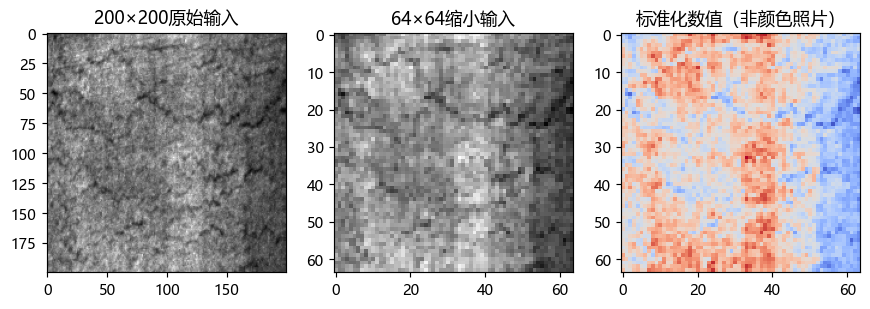

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/19_neu_input_tensor.png')

In [4]:
SIZE=64
def arrays(records):
    images=np.stack([cv2.resize(cv2.imread(str(DATA/r['image']),0),(SIZE,SIZE),interpolation=cv2.INTER_AREA) for r in records]).astype('float32')/255
    labels=np.array([r['label_id'] for r in records],dtype='int64')
    boxes=np.array([np.array(r['union_xyxy'])/[r['width'],r['height'],r['width'],r['height']] for r in records],dtype='float32')
    return images[:,None],labels,boxes
train_x,train_y,train_b=arrays(splits['train'])
val_x,val_y,val_b=arrays(splits['val'])
test_x,test_y,test_b=arrays(splits['test'])
mean,std=float(train_x.mean()),float(train_x.std())
def loader(x,y,b,shuffle):
    return DataLoader(TensorDataset(torch.from_numpy((x-mean)/std),torch.from_numpy(y),torch.from_numpy(b)),
                      batch_size=64,shuffle=shuffle,num_workers=0)
train_loader=loader(train_x,train_y,train_b,True)
val_loader=loader(val_x,val_y,val_b,False)
test_loader=loader(test_x,test_y,test_b,False)
print('训练集均值/标准差:',mean,std)
print('图像、类别、框:',train_x.shape,train_y.shape,train_b.shape)
print('一个4×4像素块:',train_x[0,0,:4,:4],sep='\n')
print('对应标准化张量:',((train_x-mean)/std)[0,0,:4,:4],sep='\n')
fig,axs=plt.subplots(1,3,figsize=(10,3))
axs[0].imshow(cv2.imread(str(DATA/splits['train'][0]['image']),0),cmap='gray');axs[0].set_title('200×200原始输入')
axs[1].imshow(train_x[0,0],cmap='gray');axs[1].set_title('64×64缩小输入')
axs[2].imshow(((train_x-mean)/std)[0,0],cmap='coolwarm');axs[2].set_title('标准化数值（非颜色照片）')
save_figure('19_neu_input_tensor')

## 4 网络结构：空间缩小，通道增加

Conv1:1→8、Conv2:8→16、Conv3:16→32；3×3卷积保持空间尺寸，2×2最大池化将宽高减半。
ReLU把负响应置0，不执行模糊。第一层8个核各观察同一灰度输入；
第二层的每个输出核有8个输入切片，先分别相关，再按输入通道求和。
PyTorch称作Conv2d的运算实现互相关，不额外翻转核。

最后的32×8×8特征分成两条支路：
全局平均池化→32维向量→6类logits；
展平→2048维→LayerNorm→64维→4个框参数。排序后得到合法的归一化xyxy。
LayerNorm稳定定位分支的输入尺度，避免特征幅值增长使末端Sigmoid饱和、框退化成整张图。

In [5]:
class IndustrialCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(1,8,3,padding=1)
        self.conv2=nn.Conv2d(8,16,3,padding=1)
        self.conv3=nn.Conv2d(16,32,3,padding=1)
        self.pool=nn.MaxPool2d(2)
        self.classifier=nn.Linear(32,6)
        self.box_norm=nn.LayerNorm(32*8*8)
        self.box_hidden=nn.Linear(32*8*8,64)
        self.box_out=nn.Linear(64,4)
    def trace(self,x):
        t={'input':x}
        for i in range(1,4):
            t[f'conv{i}']=getattr(self,f'conv{i}')(x)
            t[f'relu{i}']=F.relu(t[f'conv{i}'])
            x=self.pool(t[f'relu{i}']); t[f'pool{i}']=x
        t['gap']=F.adaptive_avg_pool2d(x,1)
        t['vector']=t['gap'].flatten(1)
        t['logits']=self.classifier(t['vector'])
        t['flat']=x.flatten(1)
        t['box_normalized']=self.box_norm(t['flat'])
        t['box_vector']=F.relu(self.box_hidden(t['box_normalized']))
        raw=self.box_out(t['box_vector']).sigmoid()
        t['boxes']=torch.cat([torch.minimum(raw[:,:2],raw[:,2:]),torch.maximum(raw[:,:2],raw[:,2:])],1)
        return t
    def forward(self,x):
        t=self.trace(x)
        return t['logits'],t['boxes']
model=IndustrialCNN().to(DEV)
initial_state=copy.deepcopy(model.state_dict())
xb,yb,bb=next(iter(train_loader))
for name,value in model.trace(xb[:1].to(DEV)).items(): print(f'{name:12s}',tuple(value.shape))
print('参数量:',sum(p.numel() for p in model.parameters()))

input        (1, 1, 64, 64)
conv1        (1, 8, 64, 64)
relu1        (1, 8, 64, 64)
pool1        (1, 8, 32, 32)
conv2        (1, 16, 32, 32)
relu2        (1, 16, 32, 32)
pool2        (1, 16, 16, 16)
conv3        (1, 32, 16, 16)
relu3        (1, 32, 16, 16)
pool3        (1, 32, 8, 8)
gap          (1, 32, 1, 1)
vector       (1, 32)
logits       (1, 6)
flat         (1, 2048)
box_normalized (1, 2048)
box_vector   (1, 64)
boxes        (1, 4)
参数量: 141578


## 5 先真实训练，再解释学到的卷积核

总损失 L=分类交叉熵+2×框回归SmoothL1。
CrossEntropyLoss直接接收logits；Softmax只用于展示概率。
验证集只选最优检查点，不更新权重。测试图不会参与训练或检查点选择。
每个epoch重新打乱训练图像，下面保留每一轮的实测曲线。

epoch 01: train CE=1.700, box=0.021, acc=0.232; val CE=1.545, box=0.013, acc=0.319


epoch 02: train CE=1.479, box=0.016, acc=0.415; val CE=1.365, box=0.013, acc=0.511


epoch 03: train CE=1.353, box=0.016, acc=0.498; val CE=1.258, box=0.013, acc=0.507


epoch 04: train CE=1.247, box=0.015, acc=0.564; val CE=1.143, box=0.012, acc=0.552


epoch 05: train CE=1.152, box=0.014, acc=0.585; val CE=1.070, box=0.012, acc=0.600


epoch 06: train CE=1.064, box=0.014, acc=0.627; val CE=1.019, box=0.012, acc=0.604


... (14 outputs left out)

epoch 21: train CE=0.287, box=0.009, acc=0.903; val CE=0.281, box=0.009, acc=0.904


epoch 22: train CE=0.291, box=0.009, acc=0.909; val CE=0.256, box=0.010, acc=0.919


epoch 23: train CE=0.247, box=0.009, acc=0.920; val CE=0.251, box=0.009, acc=0.915


epoch 24: train CE=0.238, box=0.008, acc=0.918; val CE=0.256, box=0.010, acc=0.926


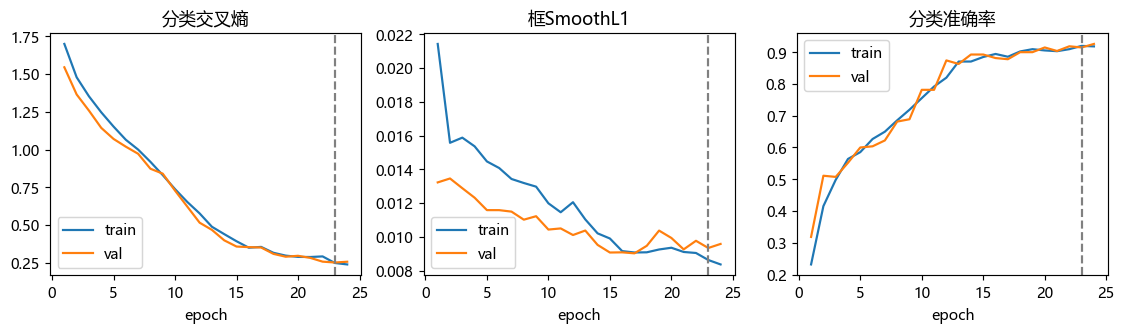

选用验证集最优epoch: 23


In [6]:
optimizer=torch.optim.Adam(model.parameters(),lr=.002)
history=[];best_loss=float('inf');best_state=None
EPOCHS=24
for epoch in range(EPOCHS):
    model.train(); totals=np.zeros(4)
    for x,y,b in train_loader:
        x,y,b=x.to(DEV),y.to(DEV),b.to(DEV)
        optimizer.zero_grad()
        logits,boxes=model(x)
        ce=F.cross_entropy(logits,y); loc=F.smooth_l1_loss(boxes,b)
        loss=ce+2*loc
        loss.backward();optimizer.step()
        totals += [float(ce.detach())*len(y),float(loc.detach())*len(y),float((logits.argmax(1)==y).sum()),len(y)]
    model.eval(); vtot=np.zeros(4)
    with torch.no_grad():
        for x,y,b in val_loader:
            x,y,b=x.to(DEV),y.to(DEV),b.to(DEV)
            logits,boxes=model(x)
            vtot += [float(F.cross_entropy(logits,y))*len(y),float(F.smooth_l1_loss(boxes,b))*len(y),float((logits.argmax(1)==y).sum()),len(y)]
    tc,tl,ta=totals[:3]/totals[3];vc,vl,va=vtot[:3]/vtot[3]
    history.append([epoch+1,tc,tl,ta,vc,vl,va])
    if vc+2*vl < best_loss:
        best_loss=vc+2*vl;best_state=copy.deepcopy(model.state_dict());best_epoch=epoch+1
    print(f'epoch {epoch+1:02d}: train CE={tc:.3f}, box={tl:.3f}, acc={ta:.3f}; val CE={vc:.3f}, box={vl:.3f}, acc={va:.3f}')
model.load_state_dict(best_state);model.eval()
torch.save({'state_dict':{k:v.cpu() for k,v in model.state_dict().items()},'mean':mean,'std':std,
            'classes':CLASSES,'best_epoch':best_epoch,'input_size':SIZE},ROOT/'outputs/19_neu_model.pt')
h=np.array(history)
np.savetxt(ROOT/'outputs/19_neu_training.csv',h,delimiter=',',header='epoch,train_ce,train_box,train_acc,val_ce,val_box,val_acc',comments='')
fig,axs=plt.subplots(1,3,figsize=(13,3))
for ax,cols,title in [(axs[0],(1,4),'分类交叉熵'),(axs[1],(2,5),'框SmoothL1'),(axs[2],(3,6),'分类准确率')]:
    ax.plot(h[:,0],h[:,cols[0]],label='train');ax.plot(h[:,0],h[:,cols[1]],label='val')
    ax.axvline(best_epoch,color='gray',ls='--');ax.set_title(title);ax.set_xlabel('epoch');ax.legend()
save_figure('19_neu_training')
print('选用验证集最优epoch:',best_epoch)

## 6 一直跟踪同一张验证图：卷积核与所有通道

为避免用测试集调解释参数，本节固定使用一张验证图。
8张Conv1输出是同一原图的8种响应；不能把通道平均后说成模型只剩一张模糊图。
所有阶段会分别输出完整通道图；色条表示响应数值，不代表原图亮度。

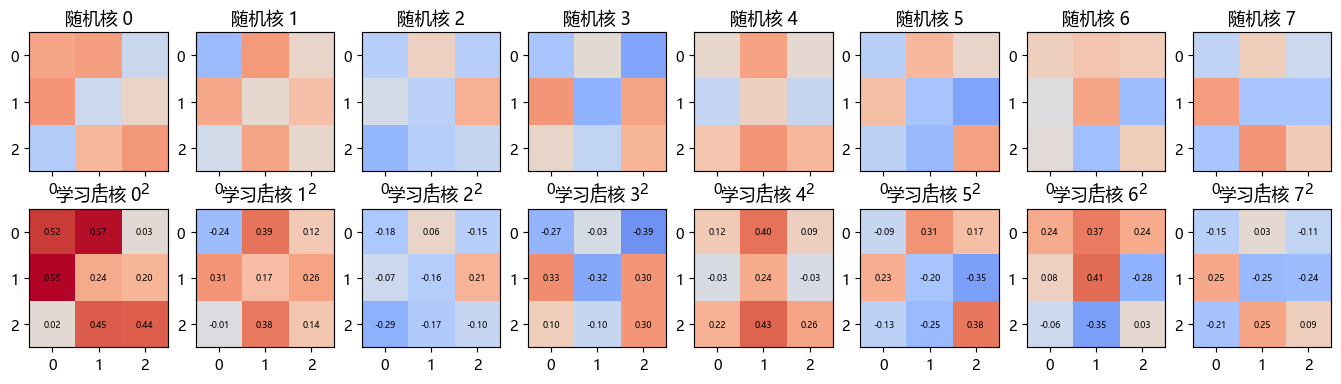

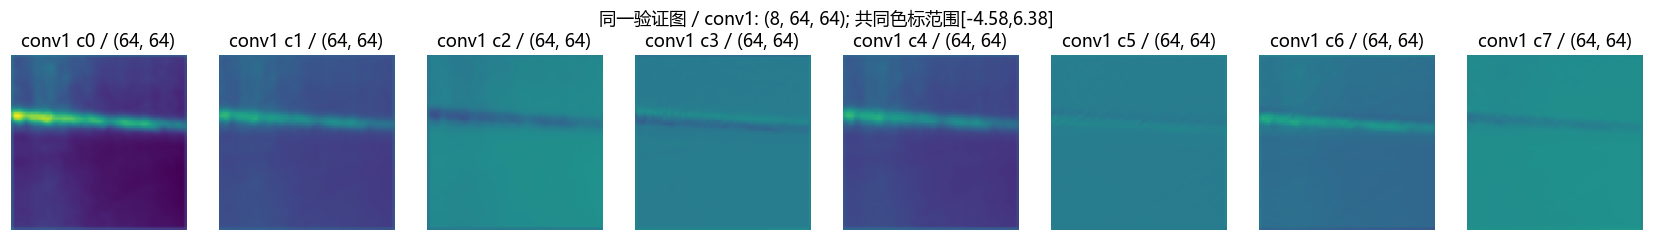

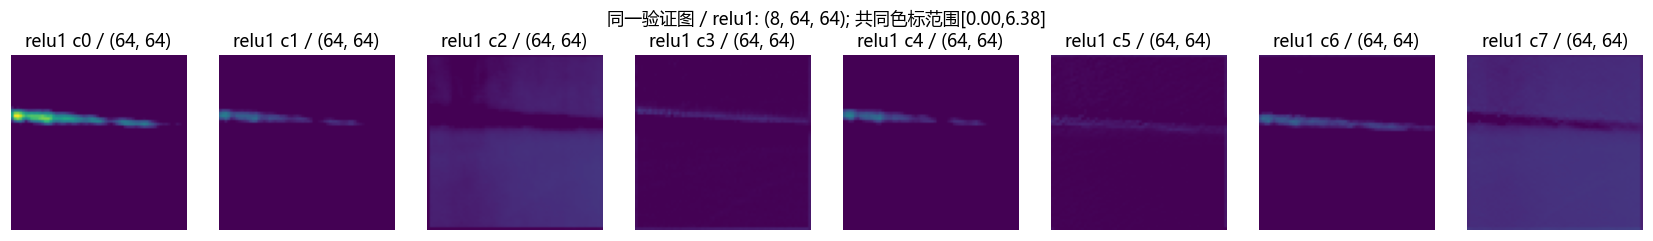

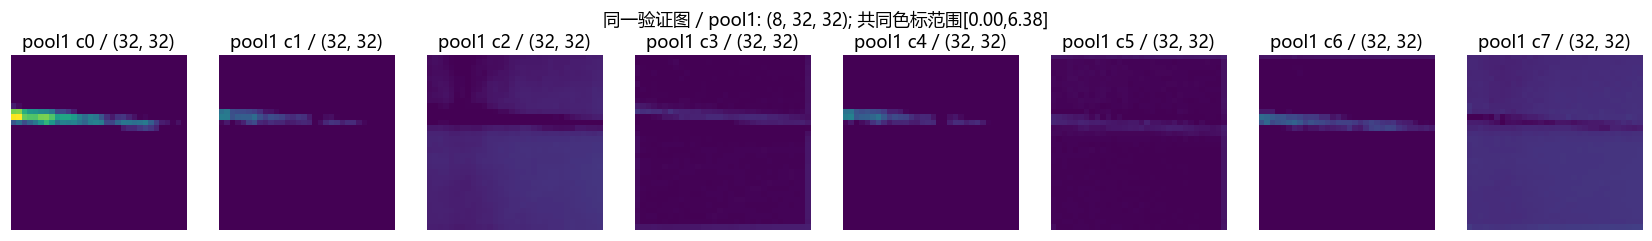

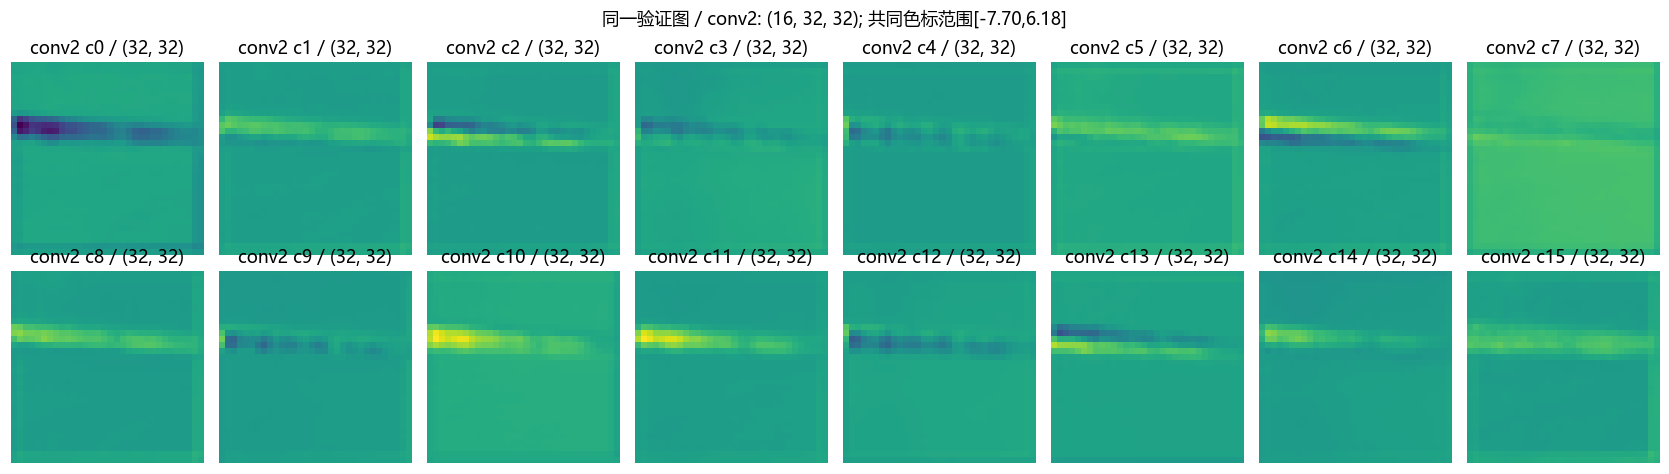

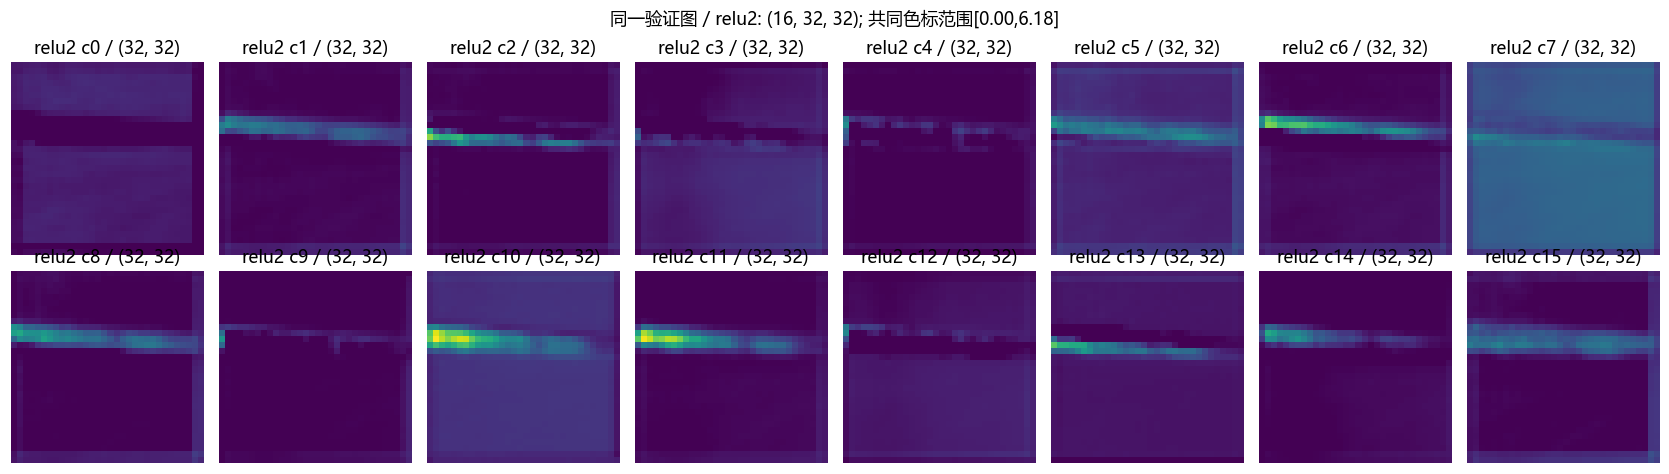

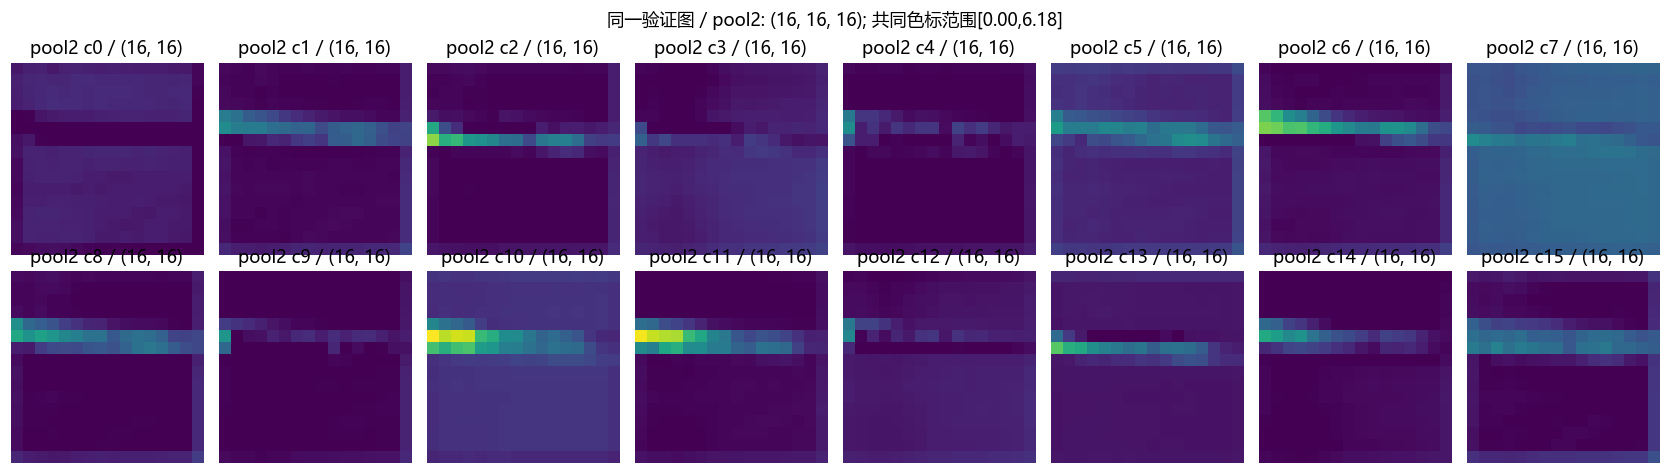

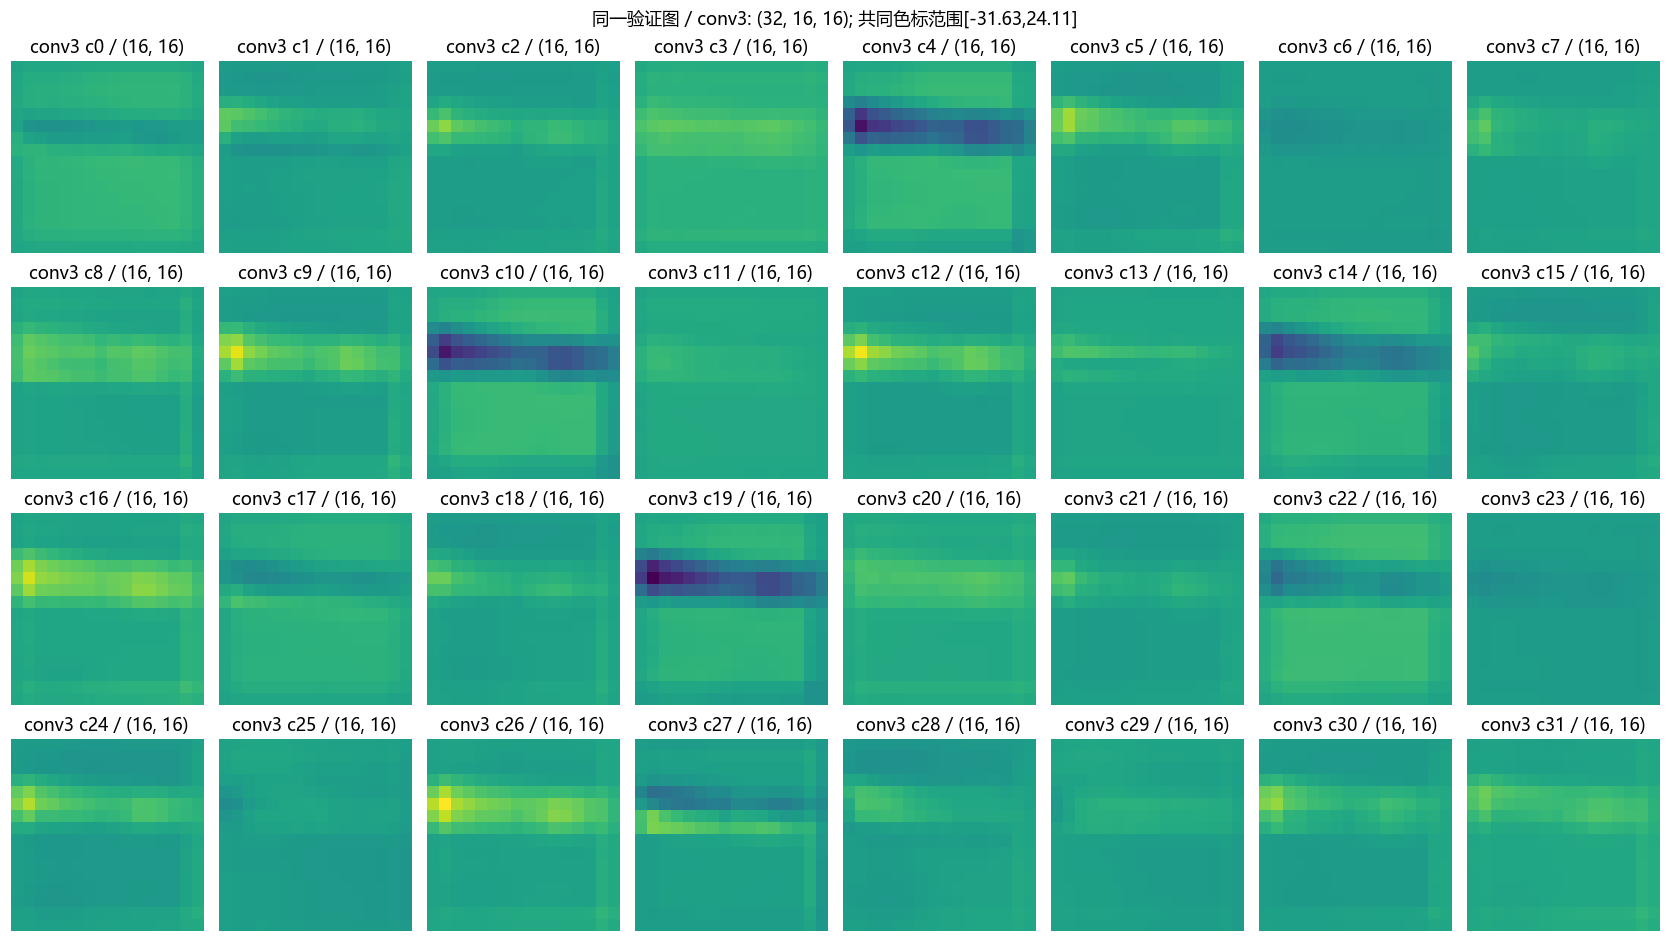

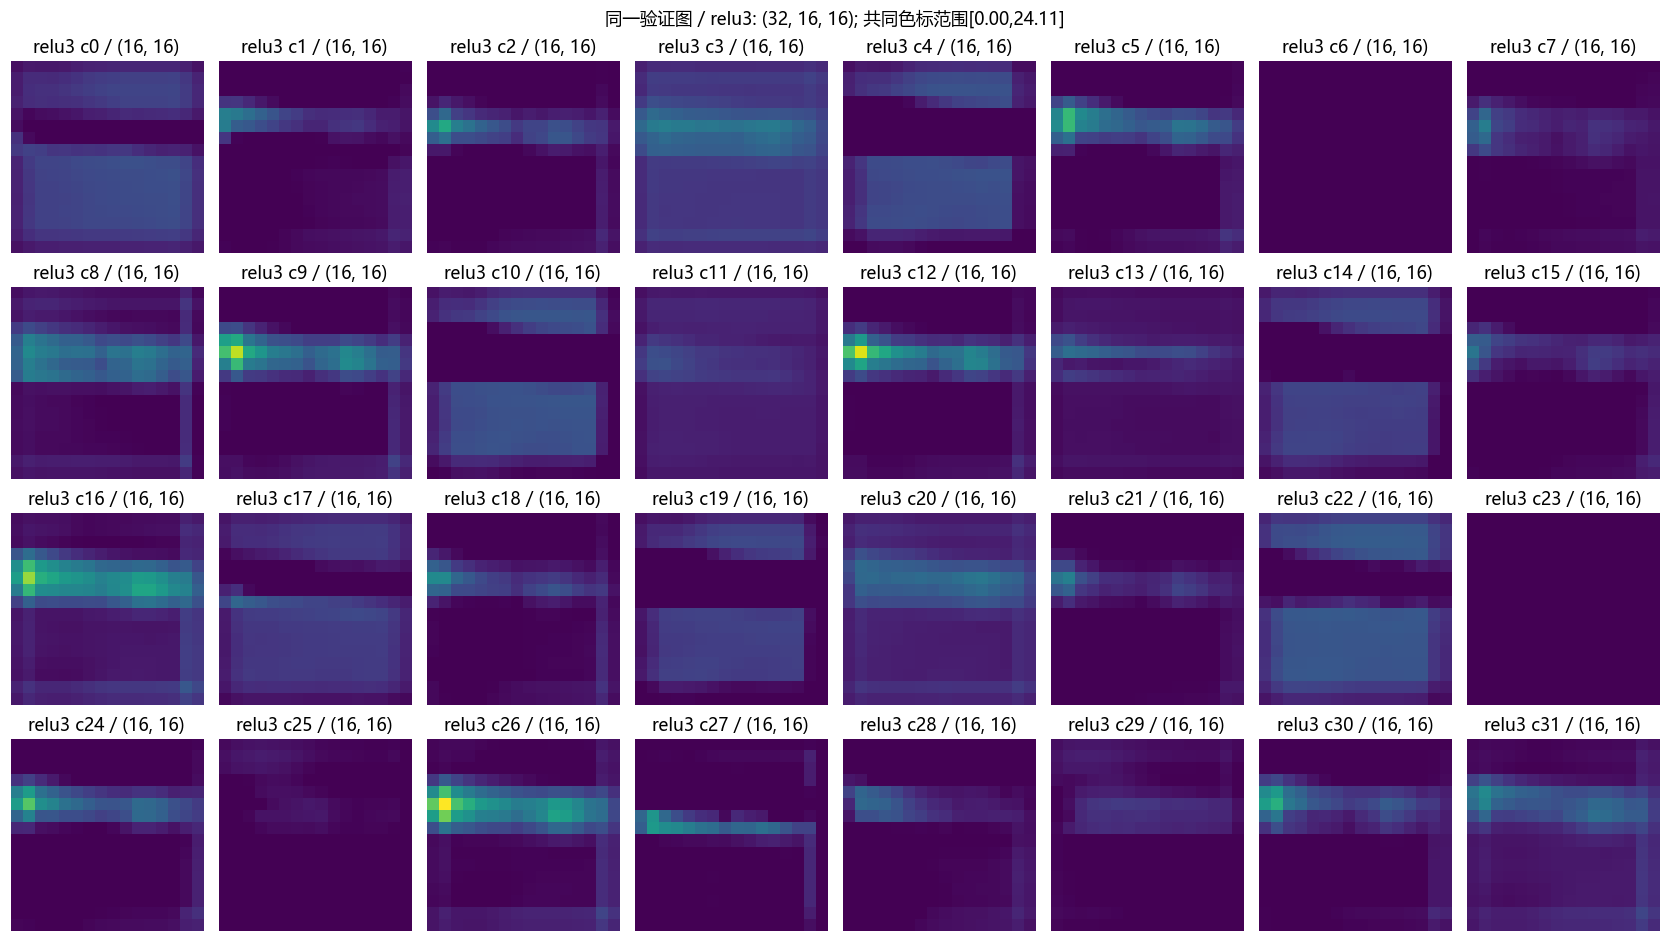

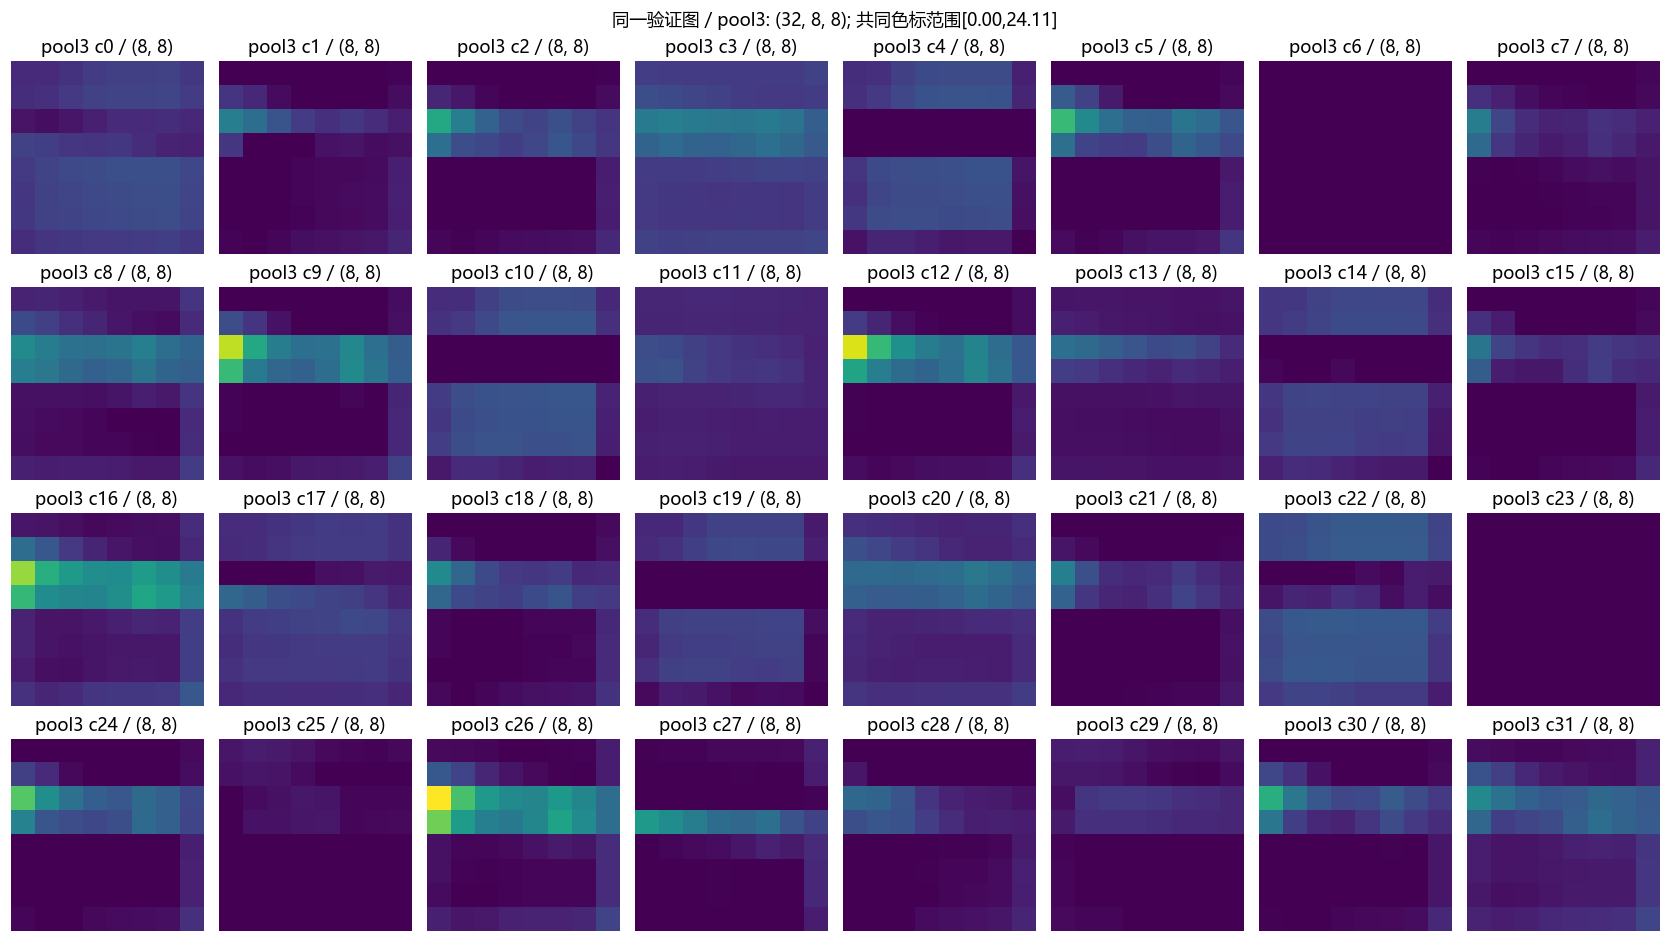

In [7]:
example_id=next(i for i,r in enumerate(splits['val']) if r['label']=='scratches')
example=torch.from_numpy((val_x[example_id:example_id+1]-mean)/std).to(DEV)
with torch.no_grad(): trace={k:v.detach().cpu().numpy() for k,v in model.trace(example).items()}
fig,axs=plt.subplots(2,8,figsize=(16,4))
old=initial_state['conv1.weight'].cpu().numpy()[:,0]
new=model.conv1.weight.detach().cpu().numpy()[:,0]
limit=max(abs(old).max(),abs(new).max())
for j in range(8):
    axs[0,j].imshow(old[j],cmap='coolwarm',vmin=-limit,vmax=limit);axs[0,j].set_title('随机核 '+str(j))
    axs[1,j].imshow(new[j],cmap='coolwarm',vmin=-limit,vmax=limit);axs[1,j].set_title('学习后核 '+str(j))
    for y in range(3):
        for x in range(3): axs[1,j].text(x,y,f'{new[j,y,x]:.2f}',ha='center',va='center',fontsize=6)
save_figure('19_neu_kernels')
for stage in ['conv1','relu1','pool1','conv2','relu2','pool2','conv3','relu3','pool3']:
    maps=trace[stage][0]; n=len(maps); cols=8; rows_n=int(np.ceil(n/cols))
    fig,axs=plt.subplots(rows_n,cols,figsize=(16,2.3*rows_n),squeeze=False)
    lo,hi=float(maps.min()),float(maps.max())
    for j,ax in enumerate(axs.flat):
        if j<n:
            ax.imshow(maps[j],cmap='viridis',vmin=lo,vmax=hi);ax.set_title(f'{stage} c{j} / {maps[j].shape}')
        ax.axis('off')
    fig.suptitle(f'同一验证图 / {stage}: {maps.shape}; 共同色标范围[{lo:.2f},{hi:.2f}]')
    fig.tight_layout()
    save_figure('19_neu_'+stage+'_channels')

## 7 手算一个真实卷积位置，不跳过乘加

取学习后的Conv1第0个3×3核，在实际输入的一个位置逐项乘，再求和加偏置。
padding=1表示边界补0；stride=1。
输出宽度=⌊(输入宽度+2padding−核宽度)/stride⌋+1。
再核对Conv2：每个输出像素要累加8个输入通道的贡献。

3×3输入:
[[-0.38540795 -0.4975217  -0.6096354 ]
 [-0.3480367  -0.46015045 -0.5348929 ]
 [ 0.02567587  0.04436149  0.08173274]]
3×3核:
[[0.51577836 0.574395   0.02508073]
 [0.5859667  0.23947269 0.20439653]
 [0.02450867 0.44820285 0.44044536]]
逐项相乘:
[[-0.19878508 -0.28577396 -0.0152901 ]
 [-0.20393792 -0.11019347 -0.10933026]
 [ 0.00062928  0.01988295  0.0359988 ]]
乘积求和 + bias = -0.37286466360092163 PyTorch输出= -0.37286466360092163


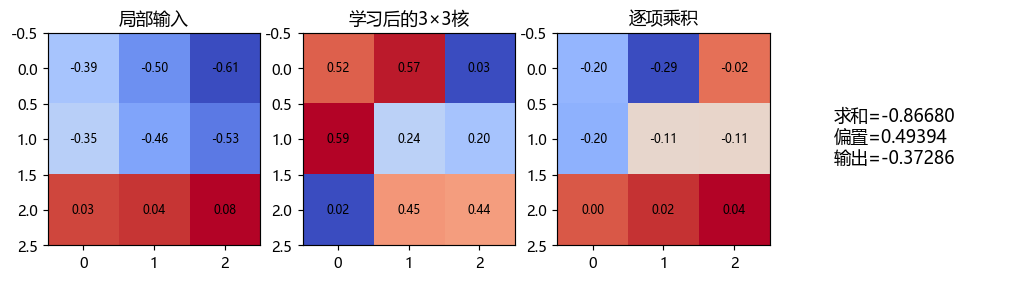

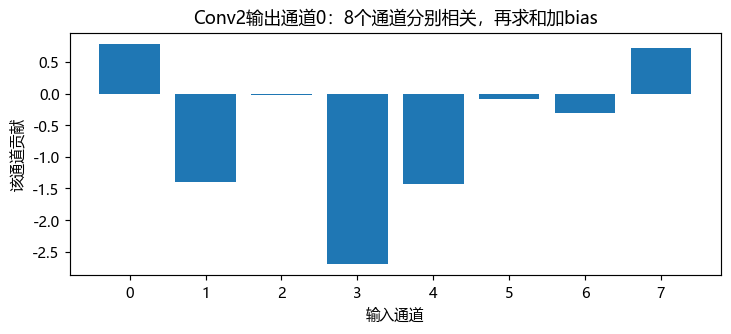

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/19_neu_channel_sum.png')

In [8]:
inp=trace['input'][0,0];weight=new[0];bias=float(model.conv1.bias[0].detach().cpu())
row,col=20,20
patch=np.pad(inp,1)[row:row+3,col:col+3];products=patch*weight
manual=float(products.sum()+bias);actual=float(trace['conv1'][0,0,row,col])
print('3×3输入:',patch,'3×3核:',weight,'逐项相乘:',products,sep='\n')
print('乘积求和 + bias =',manual,'PyTorch输出=',actual)
assert np.isclose(manual,actual,atol=1e-5)
fig,axs=plt.subplots(1,4,figsize=(12,3))
for ax,arr,title in zip(axs[:3],[patch,weight,products],['局部输入','学习后的3×3核','逐项乘积']):
    ax.imshow(arr,cmap='coolwarm');ax.set_title(title)
    for yy in range(3):
        for xx in range(3): ax.text(xx,yy,f'{arr[yy,xx]:.2f}',ha='center',va='center',fontsize=8)
axs[3].axis('off');axs[3].text(.1,.4,f'求和={products.sum():.5f}\n偏置={bias:.5f}\n输出={manual:.5f}',fontsize=12)
save_figure('19_neu_conv_arithmetic')
kernel2=model.conv2.weight.detach().cpu().numpy()[0]
previous=trace['pool1'][0];r,c=10,10
contributions=np.array([(np.pad(previous[j],1)[r:r+3,c:c+3]*kernel2[j]).sum() for j in range(8)])
value=contributions.sum()+float(model.conv2.bias[0].detach().cpu())
assert np.isclose(value,trace['conv2'][0,0,r,c],atol=1e-4)
fig,ax=plt.subplots(figsize=(8,3));ax.bar(range(8),contributions);ax.set_xlabel('输入通道');ax.set_ylabel('该通道贡献')
ax.set_title('Conv2输出通道0：8个通道分别相关，再求和加bias')
save_figure('19_neu_channel_sum')

## 8 ReLU与Pooling到底丢掉了什么

ReLU保留正响应，把负数置0；MaxPool每个2×2窗口只保留最大值。
这里把一个4×4响应、每个窗口的被选位置和2×2池化结果同时列出。
池化降低空间精度，通道数不变。反向传播只能经过被选的最大值位置；
真实卷积核训练由梯度更新，不是把图像“变成卷积核”。

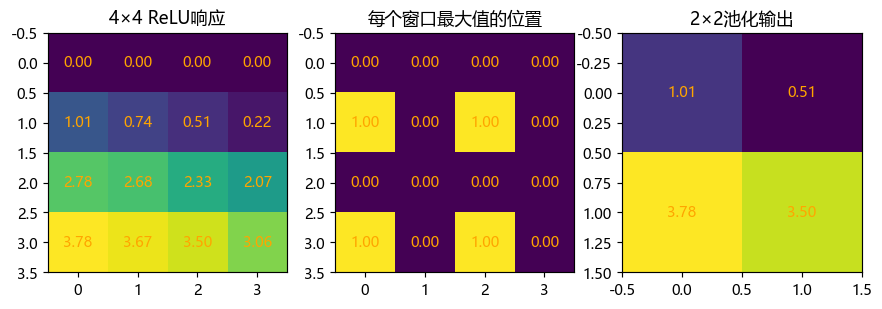

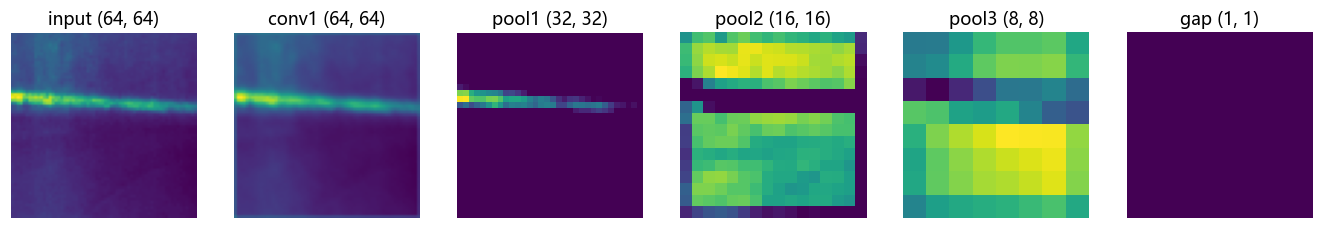

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/19_neu_spatial_journey.png')

In [9]:
block=trace['relu1'][0,0,20:24,20:24]
pooled=F.max_pool2d(torch.from_numpy(block)[None,None],2)[0,0].numpy()
selected=np.zeros_like(block)
for yy in range(2):
    for xx in range(2):
        yy0,xx0=2*yy,2*xx
        by,bx=np.unravel_index(block[yy0:yy0+2,xx0:xx0+2].argmax(),(2,2))
        selected[yy0+by,xx0+bx]=1
fig,axs=plt.subplots(1,3,figsize=(10,3))
for ax,arr,title in zip(axs,[block,selected,pooled],['4×4 ReLU响应','每个窗口最大值的位置','2×2池化输出']):
    ax.imshow(arr,cmap='viridis');ax.set_title(title)
    for yy in range(arr.shape[0]):
        for xx in range(arr.shape[1]): ax.text(xx,yy,f'{arr[yy,xx]:.2f}',ha='center',va='center',color='orange')
save_figure('19_neu_pool_arithmetic')
fig,axs=plt.subplots(1,6,figsize=(16,3))
for ax,key in zip(axs,['input','conv1','pool1','pool2','pool3','gap']):
    arr=trace[key][0,0];ax.imshow(arr,cmap='viridis');ax.set_title(key+' '+str(arr.shape));ax.axis('off')
save_figure('19_neu_spatial_journey')

## 9 从特征图到向量，再到类别与ROI

全局平均池化在每个8×8通道内部取平均，产生32个数。
分类线性层给每一类一个32维权重向量，点积加偏置得到logits，再Softmax得到概率。
定位支路保留空间布局，2048维展平向量→64维隐藏向量→4个坐标。
这两条支路共享卷积特征，但任务与监督信号不同。

32维分类向量: [4.169 1.238 1.882 5.414 3.192 2.394 0.    1.261 3.502 3.218 3.469 2.689
 3.073 2.032 2.992 1.222 5.056 3.595 1.735 2.572 4.134 1.14  4.655 0.
 2.346 0.398 4.204 1.509 1.298 1.076 1.796 3.335]
2048维定位输入: (1, 2048) 64维定位特征: (1, 64)
logits:
[-6.917803   -7.016417   -3.080902   -0.34317154 -5.7940674   5.4336843 ]
probabilities:
[4.3090108e-06 3.9043593e-06 1.9985840e-04 3.0881874e-03 1.3255914e-05
 9.9669051e-01]
预测框xyxy:
[0.01059451 0.39984062 0.9851312  0.46107635]


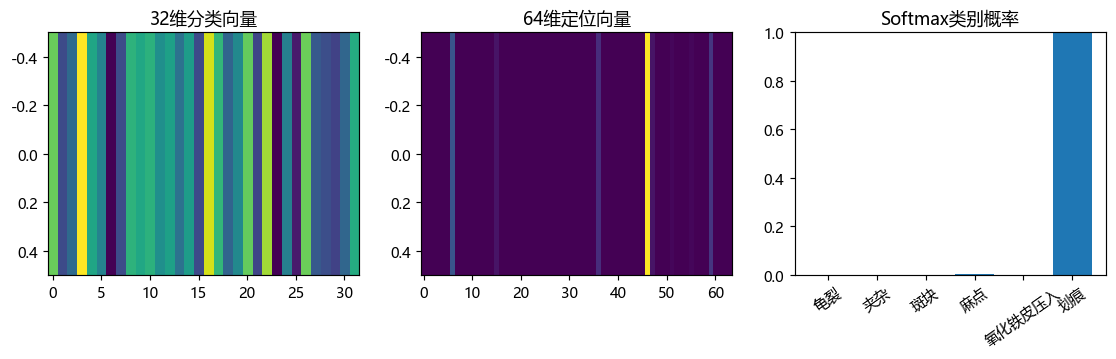

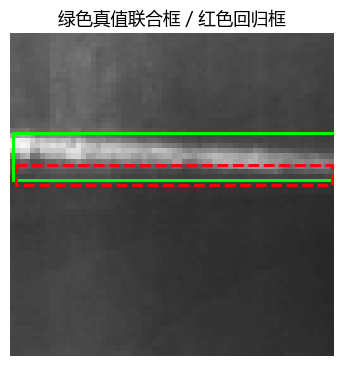

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/19_neu_predicted_roi.png')

In [10]:
vector=trace['vector'][0];logits=trace['logits'][0]
weights=model.classifier.weight.detach().cpu().numpy()
bias_cls=model.classifier.bias.detach().cpu().numpy()
assert np.allclose(weights@vector+bias_cls,logits,atol=1e-5)
prob=torch.softmax(torch.from_numpy(logits),0).numpy()
print('32维分类向量:',np.round(vector,3))
print('2048维定位输入:',trace['flat'].shape,'64维定位特征:',trace['box_vector'].shape)
print('logits:',logits,'probabilities:',prob,'预测框xyxy:',trace['boxes'][0],sep='\n')
fig,axs=plt.subplots(1,3,figsize=(13,3))
axs[0].imshow(vector[None],cmap='viridis',aspect='auto');axs[0].set_title('32维分类向量')
axs[1].imshow(trace['box_vector'],cmap='viridis',aspect='auto');axs[1].set_title('64维定位向量')
axs[2].bar(CHINESE,prob);axs[2].tick_params(axis='x',rotation=35);axs[2].set_title('Softmax类别概率');axs[2].set_ylim(0,1)
save_figure('19_neu_vectors_probabilities')
def draw_boxes(ax,image,truth,pred,title):
    ax.imshow(image,cmap='gray',vmin=0,vmax=1)
    for box,color,style in [(truth,'lime','-'),(pred,'red','--')]:
        x0,y0,x1,y1=box*SIZE
        ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color=color,lw=2,linestyle=style))
    ax.set_title(title);ax.axis('off')
fig,ax=plt.subplots(figsize=(5,4))
draw_boxes(ax,val_x[example_id,0],val_b[example_id],trace['boxes'][0],'绿色真值联合框 / 红色回归框')
save_figure('19_neu_predicted_roi')

## 10 损失怎样算，梯度怎样回到卷积核

同一验证样本上手算−log(真类概率)，并计算框的逐坐标SmoothL1。
本节只演示梯度，不执行optimizer.step，因此不把验证图用于训练。
梯度不是卷积特征图；它表示损失对参数的局部敏感程度。

真类: 划痕 手算CE: 0.00331497676559618 PyTorch CE: 0.0033149549271911383
四坐标定位损失: [[5.61218076e-05 4.98407381e-03 1.10540546e-04 1.29224616e-04]] 均值: 0.001319990260526538
总损失=CE+2×box: 0.00595493521541357


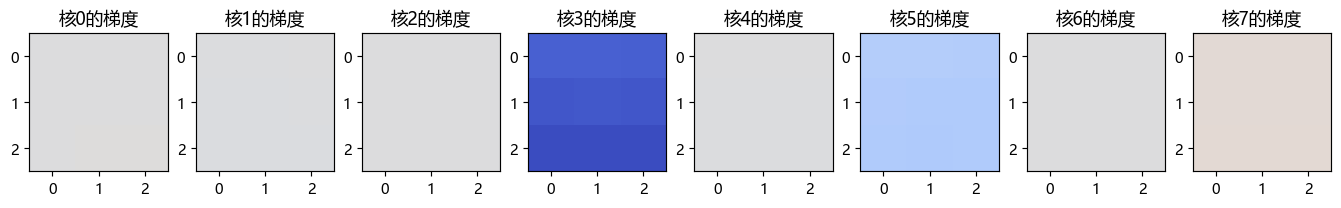

In [11]:
y=torch.tensor([val_y[example_id]],device=DEV)
b=torch.from_numpy(val_b[example_id:example_id+1]).to(DEV)
model.zero_grad()
scores,pred_box=model(example)
classification_loss=F.cross_entropy(scores,y)
coordinate_losses=F.smooth_l1_loss(pred_box,b,reduction='none')
box_loss=coordinate_losses.mean()
total_loss=classification_loss+2*box_loss
manual_ce=-np.log(max(float(prob[val_y[example_id]]),1e-12))
print('真类:',CHINESE[val_y[example_id]],'手算CE:',manual_ce,'PyTorch CE:',float(classification_loss.detach()))
print('四坐标定位损失:',coordinate_losses.detach().cpu().numpy(),'均值:',float(box_loss.detach()))
print('总损失=CE+2×box:',float(total_loss.detach()))
total_loss.backward()
gradient=model.conv1.weight.grad.detach().cpu().numpy()[:,0]
assert np.isfinite(gradient).all() and abs(gradient).max()>0
fig,axs=plt.subplots(1,8,figsize=(16,2.5))
limit=max(float(abs(gradient).max()),1e-10)
for j,ax in enumerate(axs):
    ax.imshow(gradient[j],cmap='coolwarm',vmin=-limit,vmax=limit);ax.set_title('核'+str(j)+'的梯度')
save_figure('19_neu_gradients')
model.zero_grad()

## 11 独立测试：准确率、Macro-F1、定位IoU与失败例

现在才读取测试预测。IoU比较预测联合框与真值联合框，
不等于每个缺陷实例的检测mAP。分类正确但框错误，或框覆盖了缺陷但类别错误，都是可能的。
保留全部样本ID、损失、预测框与结果CSV，不只展示最好看的例子。
同时列出“无论输入什么，都框住整张图”的IoU对照：本数据不少联合框很大，
仅看平均IoU会掩盖退化预测。这个短时训练的小模型不保证定位优于该对照。

{
  "accuracy": 0.9372693726937269,
  "macro_f1": 0.9356262925687892,
  "union_box_mean_iou": 0.5682565569877625,
  "whole_image_baseline_mean_iou": 0.5889225602149963,
  "test_images": 271,
  "best_validation_epoch": 23,
  "classification_ce": 0.21010522544384003,
  "box_smooth_l1": 0.01026223972439766,
  "protocol": "course seed42, stratified by class, grouped by exact decoded pixel hash, 70/15/15",
  "device": "cpu"
}


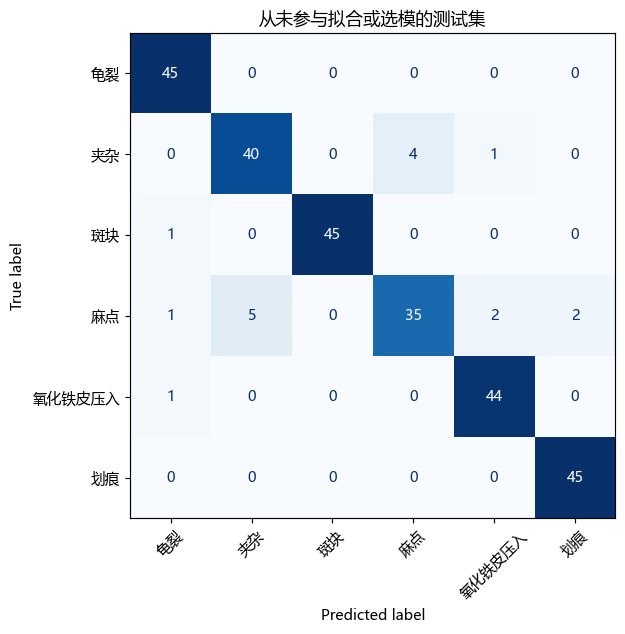

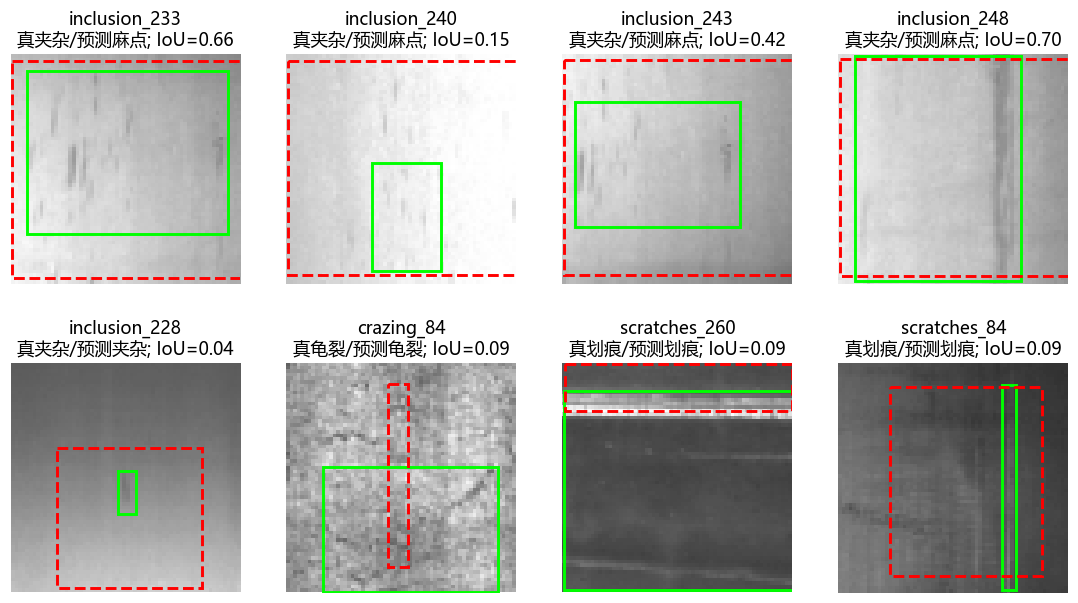

In [12]:
all_logits=[];all_boxes=[]
with torch.no_grad():
    for x,_,_ in test_loader:
        a,b=model(x.to(DEV));all_logits.append(a.cpu());all_boxes.append(b.cpu())
scores=torch.cat(all_logits);boxes=torch.cat(all_boxes)
pred=scores.argmax(1).numpy();pred_boxes=boxes.numpy()
lo=np.maximum(pred_boxes[:,:2],test_b[:,:2]);hi=np.minimum(pred_boxes[:,2:],test_b[:,2:])
intersection=np.prod(np.maximum(0,hi-lo),1)
areas=np.prod(pred_boxes[:,2:]-pred_boxes[:,:2],1)+np.prod(test_b[:,2:]-test_b[:,:2],1)-intersection
ious=intersection/np.maximum(areas,1e-8)
accuracy=float(accuracy_score(test_y,pred));macro_f1=float(f1_score(test_y,pred,average='macro'))
whole_image_iou=np.prod(test_b[:,2:]-test_b[:,:2],1)
assert float(pred_boxes.std(0).max())>.01, '定位输出退化：需检查梯度、Sigmoid饱和与框损失'
metrics={'accuracy':accuracy,'macro_f1':macro_f1,'union_box_mean_iou':float(ious.mean()),
         'whole_image_baseline_mean_iou':float(whole_image_iou.mean()),
         'test_images':len(test_y),'best_validation_epoch':best_epoch,
         'classification_ce':float(F.cross_entropy(scores,torch.from_numpy(test_y))),
         'box_smooth_l1':float(F.smooth_l1_loss(boxes,torch.from_numpy(test_b))),
         'protocol':manifest['split_protocol'],'device':str(DEV)}
(ROOT/'outputs/19_neu_metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(metrics,ensure_ascii=False,indent=2))
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(test_y,pred),display_labels=CHINESE).plot(ax=ax,colorbar=False,cmap='Blues',xticks_rotation=45)
ax.set_title('从未参与拟合或选模的测试集')
save_figure('19_neu_test_confusion')
worst=list(np.where(pred!=test_y)[0][:4])
worst += [int(i) for i in np.argsort(ious) if i not in worst][:max(0,8-len(worst))]
fig,axs=plt.subplots(2,4,figsize=(13,7))
for ax,i in zip(axs.flat,worst):
    draw_boxes(ax,test_x[i,0],test_b[i],pred_boxes[i],
               f'{splits["test"][i]["id"]}\n真{CHINESE[test_y[i]]}/预测{CHINESE[pred[i]]}; IoU={ious[i]:.2f}')
save_figure('19_neu_test_failures')
with (ROOT/'outputs/19_neu_test_predictions.csv').open('w',encoding='utf-8',newline='') as out:
    writer=csv.writer(out);writer.writerow(['id','true_class','predicted_class','union_box_iou','predicted_xyxy'])
    writer.writerows([r['id'],CLASSES[test_y[i]],CLASSES[pred[i]],float(ious[i]),json.dumps(pred_boxes[i].tolist())] for i,r in enumerate(splits['test']))

## 12 类别关注位置与学习任务的边界

因为本模型分类头恰好采用GAP+线性层，可以直接计算类别激活图CAM：
每个末层通道乘以该类别权重再相加。CAM是分类分数的空间贡献解释，
不是像素真值，不是训练时额外输入的标注，也不能替代定位头或目标检测评价。

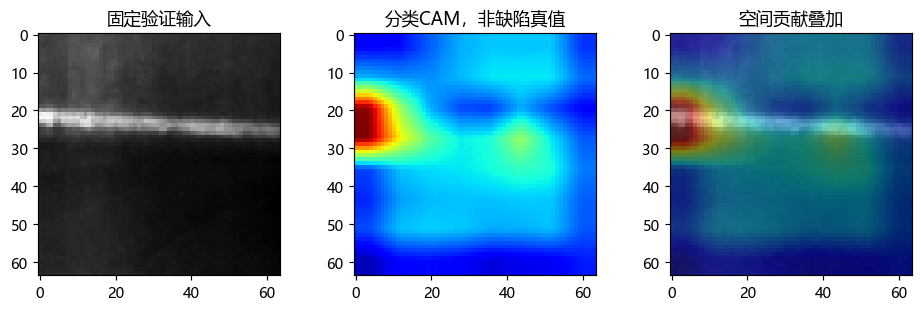

In [13]:
class_id=int(logits.argmax())
cam=np.maximum(0,(weights[class_id,:,None,None]*trace['pool3'][0]).sum(0))
cam=cv2.resize(cam,(SIZE,SIZE));cam/=max(float(cam.max()),1e-8)
fig,axs=plt.subplots(1,3,figsize=(11,3))
axs[0].imshow(val_x[example_id,0],cmap='gray');axs[0].set_title('固定验证输入')
axs[1].imshow(cam,cmap='jet',vmin=0,vmax=1);axs[1].set_title('分类CAM，非缺陷真值')
axs[2].imshow(val_x[example_id,0],cmap='gray');axs[2].imshow(cam,cmap='jet',alpha=.45,vmin=0,vmax=1);axs[2].set_title('空间贡献叠加')
save_figure('19_neu_class_activation')
assert len(rows)==1800 and scores.shape==(len(test_y),6) and boxes.shape==(len(test_y),4)

## 练习与来源

1. 改变第一层通道数后，逐层写出NCHW形状，再修改后续层的输入通道。
2. 关掉框损失，观察分类与定位两条支路；不能仅看总损失判断两个任务都学好了。
3. 比较64和96分辨率，固定划分再观察麻点和划痕类别的召回变化。
4. 隐藏ROI标注，只按图像分类；再解释为什么此时无法直接监督一个定位框。
5. 换一张手机拍摄的钢材图，保留失败例，讨论相机、尺度、光照与产线批次的分布变化。

原始数据：[东北大学NEU数据集主页](https://faculty.neu.edu.cn/songkechen/zh_CN/zdylm/263270/list/index.htm)。
下载镜像：[allanwong/NEU-DET-Steel-Surface-Defect-Detection](https://github.com/allanwong/NEU-DET-Steel-Surface-Defect-Detection)，固定commit与SHA256在manifest中。
镜像是第三方副本，不是官方新增类别或划分。本项目不将其原始数据整体作为MIT代码重新授权。
原作者论文：Song & Yan, Applied Surface Science 285 (2013), 858–864；He等，IEEE TIM 69(4) (2020), 1493–1504。
本课从零训练教学小CNN，不声称采用了最新或最优工业部署模型。